<a href="https://colab.research.google.com/github/saraswathidevikk-maker/Intermediate_Asessment/blob/main/SaraswathiDeviKK__Assessment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [123]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [124]:
np.random.seed(42)
n = 200
df = pd.DataFrame({ "order_id": range(1001, 1001 + n),
                   "order_date": pd.date_range("2024-01-01", periods=n, freq="D"), "customer_name": np.random.choice(
                   ["Anita", "Ravi", "Meera", "Arjun", "Sneha", "Karthik", "Divya", "Suresh"], n),
                    "city": np.random.choice( ["Kochi", "Chennai", "Bengaluru", "Hyderabad", "Mumbai"], n), "category": np.random.choice(
                   ["Electronics", "Clothing", "Grocery", "Books", "Furniture"], n), "quantity": np.random.randint(1, 10, n), "unit_price": np.random.randint(100, 5000, n),
                    "payment_mode": np.random.choice( ["UPI", "Card", "Cash", "NetBanking"], n),})
df.to_csv("sales_data.csv", index=False)
print("File created with", len(df), "rows")

File created with 200 rows


**Section A: Python Basics**

In [125]:
# A1.
def calculate_total(quantity, unit_price, discount_percent=0):
  total = quantity * unit_price
  discount = total * discount_percent / 100
  final_amount = total - discount
  return final_amount
print(calculate_total(3, 500))
print(calculate_total(2, 1000, 10))

1500.0
1800.0


In [126]:
# A2.
amounts = [1200, 8500, 4999, 5000, 300, 15000, 7200,950]
high = 0
low = 0
for amt in amounts:
  if amt > 5000:
    high += 1
  else:
    low += 1
print("High orders :", high)
print("Low orders :", low)

High orders : 3
Low orders : 5


In [127]:
# A3.
gst_amounts = [round(amt * 1.18, 2) for amt in amounts]
print(gst_amounts)

[1416.0, 10030.0, 5898.82, 5900.0, 354.0, 17700.0, 8496.0, 1121.0]


In [128]:
# A4.
payments = {
    "UPI": 45,
    "Card": 30,
    "Cash": 15,
    "NetBanking": 10
}
print("Highest payment mode: ", max(payments, key = payments.get))
payments["Wallet"] = 8
print(payments)

Highest payment mode:  UPI
{'UPI': 45, 'Card': 30, 'Cash': 15, 'NetBanking': 10, 'Wallet': 8}


**Section B: NumPy**

In [129]:
import numpy as np
prices = np.array([250, 1200, 450, 3000, 780, 1500, 90, 2200, 640, 4100])

In [130]:
# B1.
print("Mean:", np.mean(prices))
print("Median:", np.median(prices))
print("Minimum:", np.min(prices))
print("Maximum:", np.max(prices))
print("Standard Deviation:", np.std(prices))

Mean: 1421.0
Median: 990.0
Minimum: 90
Maximum: 4100
Standard Deviation: 1242.5252512524644


In [131]:
# B2.
filtered_prices = prices[prices > 1000]
print(filtered_prices)
print("count : ",len(filtered_prices))

[1200 3000 1500 2200 4100]
count :  5


In [132]:
# B3.
new_array = prices.reshape(2, 5)
print(new_array)
print("Row Sum :", np.sum(new_array, axis=1))
print("Column Sum :", np.sum(new_array, axis=0))

[[ 250 1200  450 3000  780]
 [1500   90 2200  640 4100]]
Row Sum : [5680 8530]
Column Sum : [1750 1290 2650 3640 4880]


In [133]:
# B4.
labels = np.where(prices >2000, "Expensive", "Affordable")
print(labels)

['Affordable' 'Affordable' 'Affordable' 'Expensive' 'Affordable'
 'Affordable' 'Affordable' 'Expensive' 'Affordable' 'Expensive']


**Section C: Pandas**

In [134]:
import pandas as pd
sales = pd.read_csv("sales_data.csv", parse_dates=["order_date"])

In [135]:
# C1.
sales.head()

,order_id,order_date,customer_name,city,category,quantity,unit_price,payment_mode
0,1001,2024-01-01,Divya,Kochi,Electronics,5,766,Card
1,1002,2024-01-02,Arjun,Hyderabad,Electronics,4,4288,UPI
2,1003,2024-01-03,Sneha,Mumbai,Grocery,5,771,UPI
3,1004,2024-01-04,Divya,Hyderabad,Furniture,7,2069,UPI
4,1005,2024-01-05,Meera,Mumbai,Clothing,9,4256,UPI


In [136]:
sales.tail(3)

,order_id,order_date,customer_name,city,category,quantity,unit_price,payment_mode
197,1198,2024-07-16,Arjun,Chennai,Electronics,9,1022,Cash
198,1199,2024-07-17,Sneha,Chennai,Books,3,519,Card
199,1200,2024-07-18,Meera,Kochi,Grocery,3,2304,UPI


In [137]:
print(sales.shape)
print(sales.columns)
print(sales.dtypes)
sales.describe()
print(sales.isnull().sum())

(200, 8)
Index(['order_id', 'order_date', 'customer_name', 'city', 'category',
       'quantity', 'unit_price', 'payment_mode'],
      dtype='object')
order_id                  int64
order_date       datetime64[ns]
customer_name            object
city                     object
category                 object
quantity                  int64
unit_price                int64
payment_mode             object
dtype: object
order_id         0
order_date       0
customer_name    0
city             0
category         0
quantity         0
unit_price       0
payment_mode     0
dtype: int64


In [138]:
# C2.
sales["total_amount"] = sales["quantity"] * sales["unit_price"]
sales.head()

,order_id,order_date,customer_name,city,category,quantity,unit_price,payment_mode,total_amount
0,1001,2024-01-01,Divya,Kochi,Electronics,5,766,Card,3830
1,1002,2024-01-02,Arjun,Hyderabad,Electronics,4,4288,UPI,17152
2,1003,2024-01-03,Sneha,Mumbai,Grocery,5,771,UPI,3855
3,1004,2024-01-04,Divya,Hyderabad,Furniture,7,2069,UPI,14483
4,1005,2024-01-05,Meera,Mumbai,Clothing,9,4256,UPI,38304


In [139]:
sales["month"] = sales["order_date"].dt.month_name()
sales.head()

,order_id,order_date,customer_name,city,category,quantity,unit_price,payment_mode,total_amount,month
0,1001,2024-01-01,Divya,Kochi,Electronics,5,766,Card,3830,January
1,1002,2024-01-02,Arjun,Hyderabad,Electronics,4,4288,UPI,17152,January
2,1003,2024-01-03,Sneha,Mumbai,Grocery,5,771,UPI,3855,January
3,1004,2024-01-04,Divya,Hyderabad,Furniture,7,2069,UPI,14483,January
4,1005,2024-01-05,Meera,Mumbai,Clothing,9,4256,UPI,38304,January


In [140]:
# C3.
result = sales[(sales["city"] == "Kochi") & (sales["category"] == "Electronics")]
print(result)

     order_id order_date customer_name   city     category  quantity  \
0        1001 2024-01-01         Divya  Kochi  Electronics         5   
16       1017 2024-01-17         Arjun  Kochi  Electronics         8   
28       1029 2024-01-29        Suresh  Kochi  Electronics         1   
34       1035 2024-02-04       Karthik  Kochi  Electronics         3   
58       1059 2024-02-28         Meera  Kochi  Electronics         5   
64       1065 2024-03-05         Divya  Kochi  Electronics         2   
78       1079 2024-03-19         Divya  Kochi  Electronics         8   
107      1108 2024-04-17         Arjun  Kochi  Electronics         1   
123      1124 2024-05-03         Divya  Kochi  Electronics         6   
160      1161 2024-06-09         Divya  Kochi  Electronics         2   
175      1176 2024-06-24       Karthik  Kochi  Electronics         5   

     unit_price payment_mode  total_amount     month  
0           766         Card          3830   January  
16         2361          

In [141]:
result = sales[(sales["total_amount"] > 20000) | (sales["payment_mode"] == "cash")]
print(result)
print("Number of rows :", len(result))

     order_id order_date customer_name       city     category  quantity  \
4        1005 2024-01-05         Meera     Mumbai     Clothing         9   
5        1006 2024-01-06        Suresh     Mumbai     Clothing         7   
6        1007 2024-01-07         Sneha  Bengaluru      Grocery         5   
7        1008 2024-01-08         Sneha     Mumbai     Clothing         7   
12       1013 2024-01-13         Meera  Hyderabad  Electronics         9   
17       1018 2024-01-18        Suresh     Mumbai        Books         9   
20       1021 2024-01-21       Karthik  Hyderabad     Clothing         5   
22       1023 2024-01-23          Ravi  Hyderabad      Grocery         6   
24       1025 2024-01-25         Arjun    Chennai     Clothing         8   
30       1031 2024-01-31         Sneha  Bengaluru     Clothing         9   
33       1034 2024-02-03          Ravi     Mumbai    Furniture         6   
35       1036 2024-02-05         Sneha  Bengaluru    Furniture         6   
42       104

In [142]:
# C4.
category_sales = sales.groupby("category")["total_amount"].sum()
print(category_sales)

category
Books          582174
Clothing       573595
Electronics    514904
Furniture      374796
Grocery        320430
Name: total_amount, dtype: int64


In [143]:
city_average = sales.groupby("city")["total_amount"].mean()
print(city_average)

city
Bengaluru    11816.636364
Chennai       9492.896552
Hyderabad    11078.043478
Kochi        11108.921569
Mumbai       16484.266667
Name: total_amount, dtype: float64


In [144]:
payment_mode = sales.groupby("payment_mode")["order_id"].count()
print(payment_mode)

payment_mode
Card          48
Cash          51
NetBanking    45
UPI           56
Name: order_id, dtype: int64


In [145]:
customer_spending = sales.groupby("customer_name")["total_amount"].sum()
top_customers = customer_spending.sort_values(ascending=False).head(3)
print(top_customers)

customer_name
Divya    369485
Sneha    350522
Ravi     315386
Name: total_amount, dtype: int64


In [146]:
# C5.
highest_orders = sales.sort_values(by="total_amount", ascending=False).head(5)
print(highest_orders)

     order_id order_date customer_name       city  category  quantity  \
30       1031 2024-01-31         Sneha  Bengaluru  Clothing         9   
114      1115 2024-04-24         Divya     Mumbai     Books         9   
63       1064 2024-03-04         Anita      Kochi  Clothing         9   
24       1025 2024-01-25         Arjun    Chennai  Clothing         8   
4        1005 2024-01-05         Meera     Mumbai  Clothing         9   

     unit_price payment_mode  total_amount    month  
30         4921          UPI         44289  January  
114        4849          UPI         43641    April  
63         4818   NetBanking         43362    March  
24         4820   NetBanking         38560  January  
4          4256          UPI         38304  January  


In [170]:
# C6.
pivot = pd.pivot_table(sales, values="total_amount", index="city", columns="category", aggfunc="sum", fill_value=0)
print(pivot)

category    Books  Clothing  Electronics  Furniture  Grocery
city                                                        
Bengaluru  118853    110038        53351     140011    97679
Chennai     40041     49783       111094      51093    23283
Hyderabad  116090    121858       127663      77282    66697
Kochi      152097    170249       122375      48508    73326
Mumbai     155093    121667       100421      57902    59445


**Section D Matplotlib and Seaborn**

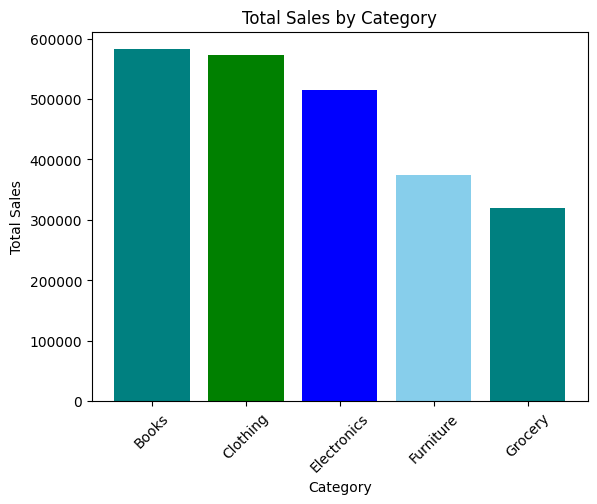

In [148]:
# D1
category_sales = sales.groupby("category")["total_amount"].sum()
plt.bar(category_sales.index, category_sales.values, color = ["Teal", "Green", "Blue", "Skyblue"])
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()


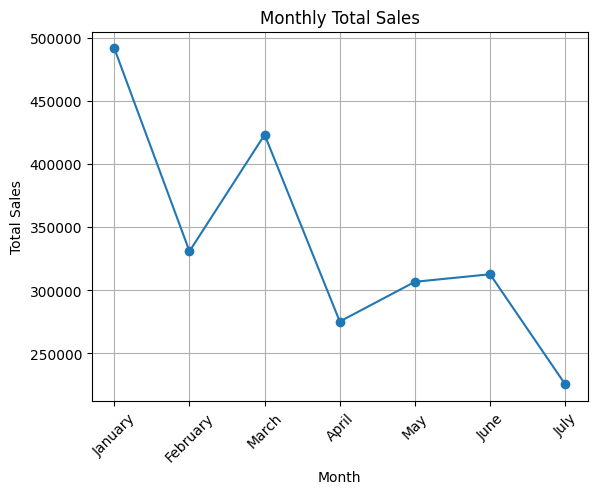

In [149]:
# D2.
monthly_sales = sales.groupby(sales["order_date"].dt.month)["total_amount"].sum()
monthly_sales.index = pd.to_datetime(monthly_sales.index, format="%m").month_name()
month_order = ["January", "February", "March", "April", "May", "June", "July"]
monthly_sales = monthly_sales.reindex(month_order)
plt.plot(monthly_sales.index, monthly_sales.values, marker='o')
plt.title("Monthly Total Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

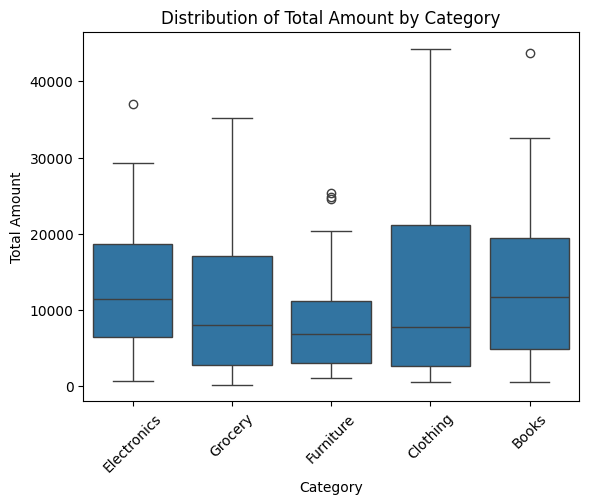

In [150]:
# D3.
sns.boxplot(data = sales, x = "category", y = "total_amount")
plt.title("Distribution of Total Amount by Category")
plt.xlabel("Category")
plt.ylabel("Total Amount")
plt.xticks(rotation=45)
plt.show()

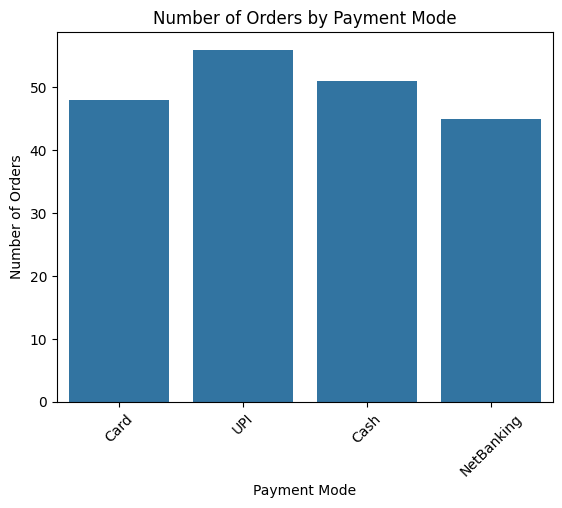

In [151]:
# D4.
sns.countplot(data = sales, x = "payment_mode")
plt.title("Number of Orders by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

**Section E: SQL with SQLite3 and MySQL**

In [152]:
# E1.
conn = sqlite3.connect("sales.db")
cursor = conn.cursor()
cursor.execute("""
CREATE TABLE IF NOT EXISTS orders (
    order_id INTEGER PRIMARY KEY,
    order_date TEXT,
    customer_name TEXT,
    city TEXT,
    category TEXT,
    quantity INTEGER,
    unit_price INTEGER,
    payment_mode TEXT
)
""")
conn.commit()
print("Database and table created successfully")

Database and table created successfully


In [153]:
# E2.
original_columns = [
    "order_id", "order_date", "customer_name",
    "city", "category", "quantity",
    "unit_price", "payment_mode"
]

db_sales = sales[original_columns].copy()
db_sales["order_date"] = db_sales["order_date"].astype(str)
db_sales.to_sql("orders", conn, if_exists="append", index=False)
result = pd.read_sql_query("SELECT COUNT(*) AS total_rows FROM orders", conn)
print(result)

   total_rows
0         200


In [154]:
# E3.
query1 = """ SELECT * FROM orders WHERE city = 'Mumbai' """
result1 = pd.read_sql_query(query1, conn)
print(result1)

    order_id  order_date customer_name    city     category  quantity  \
0       1003  2024-01-03         Sneha  Mumbai      Grocery         5   
1       1005  2024-01-05         Meera  Mumbai     Clothing         9   
2       1006  2024-01-06        Suresh  Mumbai     Clothing         7   
3       1008  2024-01-08         Sneha  Mumbai     Clothing         7   
4       1010  2024-01-10          Ravi  Mumbai    Furniture         3   
5       1016  2024-01-16         Sneha  Mumbai        Books         7   
6       1018  2024-01-18        Suresh  Mumbai        Books         9   
7       1034  2024-02-03          Ravi  Mumbai    Furniture         6   
8       1039  2024-02-08         Anita  Mumbai        Books         7   
9       1055  2024-02-24         Divya  Mumbai     Clothing         6   
10      1063  2024-03-03         Sneha  Mumbai     Clothing         4   
11      1068  2024-03-08         Anita  Mumbai    Furniture         1   
12      1075  2024-03-15         Sneha  Mumbai     

In [155]:
query2 = """ SELECT category, SUM(quantity) AS total_quantity FROM orders GROUP BY category """
result2  = pd.read_sql_query(query2, conn)
print(result2)

      category  total_quantity
0        Books             228
1     Clothing             213
2  Electronics             189
3    Furniture             180
4      Grocery             153


In [156]:
query3 = """SELECT city, AVG(unit_price) AS average_price FROM orders GROUP BY city HAVING AVG(unit_price) > 2500 """
result3 = pd.read_sql_query(query3, conn)
print(result3)

        city  average_price
0  Bengaluru    2525.340909
1  Hyderabad    2602.717391
2     Mumbai    2919.166667


In [157]:
query4 = """ SELECT *, quantity * unit_price AS total_amount FROM orders ORDER BY total_amount DESC LIMIT 5 """
result4 = pd.read_sql_query(query4, conn)
print(result4)

   order_id  order_date customer_name       city  category  quantity  \
0      1031  2024-01-31         Sneha  Bengaluru  Clothing         9   
1      1115  2024-04-24         Divya     Mumbai     Books         9   
2      1064  2024-03-04         Anita      Kochi  Clothing         9   
3      1025  2024-01-25         Arjun    Chennai  Clothing         8   
4      1005  2024-01-05         Meera     Mumbai  Clothing         9   

   unit_price payment_mode  total_amount  
0        4921          UPI         44289  
1        4849          UPI         43641  
2        4818   NetBanking         43362  
3        4820   NetBanking         38560  
4        4256          UPI         38304  


In [158]:
conn.close()

# E4

CREATE DATABASE retail_db;

USE retail_db;

CREATE TABLE customers (
    customer_id INT PRIMARY KEY AUTO_INCREMENT,
    name VARCHAR(50),
    city VARCHAR(50),
    joined_date DATE);

INSERT INTO customers
(name, city, joined_date)
VALUES
('Anita', 'Kochi', '2024-01-15'),
('Ravi', 'Chennai', '2024-02-20');

SELECT * FROM customers;

# E5

1.
SQLite is a lightweight, file-based relational database management system. It stores the entire database in a single file on the computer.
- It does not require a separate database server.
- It is easy to install, configure and use.
- It requires very little system memory and storage.
- It is suitable for small applications, mobile apps and personal projects.
- It is mainly used when the application needs simple data storage and does not require many users accessing the database at the same time.
- Examples include mobile applications, desktop applications and small websites.


2.
MySQL is a server-based relational database management system used to store, manage and organize large amounts of data.
- It requires a database server to manage data.
- It supports multiple users accessing the database at the same time.
- It provides features for user management, security and access control.
- It is suitable for large applications, websites and business systems.
- It can handle large amounts of data and multiple database operations.
- Examples include e-commerce websites, banking systems and large business applications.

**Section F: Mini ETL Pipeline**

In [171]:
# F1.
df = pd.read_csv("sales_data.csv")
df.head()


,order_id,order_date,customer_name,city,category,quantity,unit_price,payment_mode
0,1001,2024-01-01,Divya,Kochi,Electronics,5,766,Card
1,1002,2024-01-02,Arjun,Hyderabad,Electronics,4,4288,UPI
2,1003,2024-01-03,Sneha,Mumbai,Grocery,5,771,UPI
3,1004,2024-01-04,Divya,Hyderabad,Furniture,7,2069,UPI
4,1005,2024-01-05,Meera,Mumbai,Clothing,9,4256,UPI


In [172]:
def extract_data(file_path):
    df = pd.read_csv(file_path)
    print("Rows loaded:", len(df))
    return df

In [173]:
# F2.
def transform_data(df):
    df["total_amount"] = df["quantity"] * df["unit_price"]
    df["order_date"] = pd.to_datetime(df["order_date"])
    df["order_size"] ="Small"
    df.loc[df["total_amount"] >= 5000, "order_size"] = "Medium"
    df.loc[df["total_amount"] >= 15000, "order_size"] = "Large"
    df=df.drop_duplicates(subset="order_id")
    df=df[["order_id","order_date","city","total_amount","order_size"]]
    return df

In [166]:
# F3.
def load(df, db_name, csv_name):
    conn = sqlite3.connect(db_name)
    df.to_sql("clean_orders",
              conn,
              if_exists="replace",
              index=False)
    df.to_csv(csv_name, index=False)
    print("Data saved successfully to database and CSV")
    conn.close()

In [168]:
# F4.
data = extract_data("sales_data.csv")
clean_data = transform_data(data)
load(clean_data, "sales.db", "clean_orders.csv")

Rows loaded: 200
Data saved successfully to database and CSV


In [169]:
conn = sqlite3.connect("sales.db")
query = """SELECT order_size, COUNT(*) AS total_orders FROM clean_orders GROUP BY order_size """
result = pd.read_sql_query(query, conn)
print(result)
conn.close()

  order_size  total_orders
0      Large            65
1     Medium            74
2      Small            61


**ETL vs ELT**

ETL stands for Extract, Transform and Load. In this process, data is extracted from a source, cleaned and transformed, and then loaded into the destination.

ELT stands for Extract, Load and Transform. Here, data is extracted and loaded into the destination first, and the transformation is done afterwards.

The main difference is the order of loading and transformation.

In my project, I used ETL. I extracted sales data from a CSV file, transformed it using Python and Pandas, and loaded the processed data into an SQLite database and a new CSV file.